# Object Detection Perangkat Komputer - YOLO11

Objek: Keyboard, Mouse, PC, dan Monitor.

## 1. Instalasi pustaka

**Tujuan:** Memasang pustaka yang diperlukan. Aktifkan perintah instalasi jika pustaka belum tersedia.

In [1]:
# Opsional jika pustaka belum terpasang:
# %pip install ultralytics matplotlib pandas pillow pyyaml cv2-enumerate-cameras


## 2. Import pustaka

**Tujuan:** Mengimpor pustaka yang diperlukan untuk pengolahan dataset, training, evaluasi, dan inference.

In [2]:
%matplotlib inline
from pathlib import Path
from collections import Counter
import tempfile, shutil, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml, torch, cv2
runtime = tempfile.TemporaryDirectory(prefix='yolo11_runtime_')
os.environ['YOLO_CONFIG_DIR'] = runtime.name
from IPython.utils.capture import capture_output
with capture_output():
    from ultralytics import YOLO, settings
from ultralytics.utils import LOGGER
settings.update({'weights_dir': str(Path(runtime.name) / 'weights')})
from IPython.display import HTML, display
from contextlib import contextmanager
from html import escape

def tabel(judul, data, persen=()):
    df = pd.DataFrame(data).copy()
    for kolom in persen:
        if kolom in df:
            df[kolom] = df[kolom].map(lambda nilai: f'{float(nilai) * 100:.2f}%')
    css = '<style>.cv-table{border-collapse:collapse;font-size:13px;min-width:420px;color:inherit;background:transparent}.cv-table th{text-align:left;font-weight:600;background:transparent!important;color:inherit!important}.cv-table td,.cv-table th{padding:7px 12px;border-bottom:1px solid var(--vscode-panel-border,#888);color:inherit!important}.cv-table tbody tr,.cv-table tbody tr:nth-child(even){background:transparent!important;color:inherit!important}</style>'
    isi = df.to_html(index=False, classes='cv-table', border=0, float_format=lambda nilai: f'{nilai:.4f}')
    display(HTML(css + '<div style="overflow-x:auto"><h4>' + escape(judul) + '</h4>' + isi + '</div>'))

@contextmanager
def log_ringkas():
    semula = LOGGER.disabled
    try:
        LOGGER.disabled = True
        with capture_output() as log:
            yield
    except Exception:
        LOGGER.disabled = semula
        print((log.stdout + log.stderr)[-4000:])
        raise
    finally:
        LOGGER.disabled = semula

BASE = Path.cwd()
DATASET = BASE / 'dataset'
BEST = BASE / 'best.pt'
assert (DATASET / 'data.yaml').is_file(), 'Buka notebook dari folder CODING.'
source_names = yaml.safe_load((DATASET / 'data.yaml').read_text())['names']
names = ['keyboard', 'mouse', 'pc', 'monitor']
MAP_ID = {source_names.index(name): i for i, name in enumerate(names)}
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
manifest = json.loads((DATASET / 'manifest.json').read_text())


## 3. Pemeriksaan

**Tujuan:** Memeriksa jumlah gambar, distribusi kelas, dan anotasi melalui contoh bounding box.

Split,Gambar,Anotasi,Persentase
train,485,993,70.39%
valid,118,228,17.13%
test,86,153,12.48%


Kelas,train,valid,test,Total
keyboard,216,32,19,267
mouse,191,33,14,238
pc,135,35,22,192
monitor,451,128,98,677


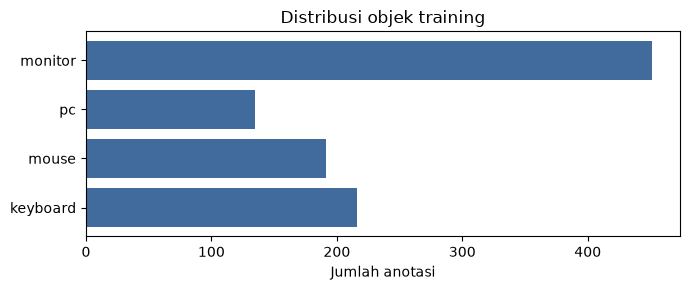

In [3]:
def baca_box(line):
    v = list(map(float, line.split()))
    if len(v) < 5 or not all(np.isfinite(v)):
        raise ValueError('Anotasi tidak lengkap/nonfinite.')
    cid = int(v[0])
    if cid != v[0] or not 0 <= cid < len(source_names):
        raise ValueError('ID kelas tidak valid.')
    if not all((0 <= z <= 1 for z in v[1:])):
        raise ValueError('Koordinat harus 0-1.')
    if len(v) == 5:
        x, y, w, h = v[1:]
    elif len(v) >= 7 and (len(v) - 1) % 2 == 0:
        xs, ys = (v[1::2], v[2::2])
        x, y = ((min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2)
        w, h = (max(xs) - min(xs), max(ys) - min(ys))
    else:
        raise ValueError('Format anotasi tidak valid.')
    if w <= 0 or h <= 0:
        raise ValueError('Box kosong.')
    if min(x - w / 2, y - h / 2) < -1e-06 or max(x + w / 2, y + h / 2) > 1 + 1e-06:
        raise ValueError('Box keluar dari gambar.')
    return (cid, x, y, w, h)
ringkasan, distribusi = ([], {})
for split in ['train', 'valid', 'test']:
    images = list((DATASET / split / 'images').glob('*.jpg'))
    counts = Counter()
    for image in images:
        label = DATASET / split / 'labels' / (image.stem + '.txt')
        assert label.exists(), f'Label hilang: {label}'
        for line in label.read_text().splitlines():
            if line.strip():
                cid = baca_box(line)[0]
                if cid in MAP_ID:
                    counts[MAP_ID[cid]] += 1
    ringkasan.append({'split': split, 'gambar': len(images), 'objek': sum(counts.values())})
    distribusi[split] = {name: counts[i] for i, name in enumerate(names)}
df_split = pd.DataFrame(ringkasan).rename(columns={'split': 'Split', 'gambar': 'Gambar', 'objek': 'Anotasi'})
df_split['Persentase'] = df_split.Gambar / df_split.Gambar.sum()
tabel('Jumlah gambar dan anotasi', df_split, persen=['Persentase'])
df_kelas = pd.DataFrame(distribusi).rename_axis('Kelas').reset_index()
df_kelas['Total'] = df_kelas[['train', 'valid', 'test']].sum(axis=1)
tabel('Distribusi anotasi per kelas', df_kelas)
plt.figure(figsize=(7, 3))
plt.barh(names, [distribusi['train'][name] for name in names], color='#406b9c')
plt.xlabel('Jumlah anotasi')
plt.title('Distribusi objek training')
plt.tight_layout()
plt.show()


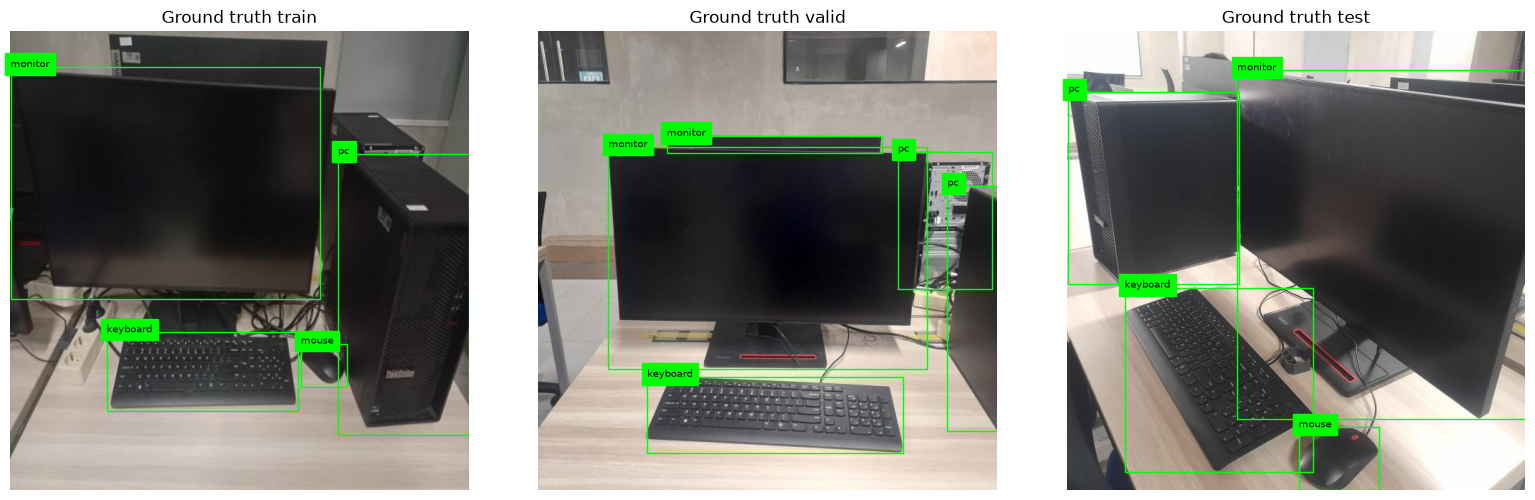

In [4]:
def tampil_label(path, ax):
    image = Image.open(path).convert('RGB')
    w, h = image.size
    ax.imshow(image)
    label = path.parent.parent / 'labels' / (path.stem + '.txt')
    for line in label.read_text().splitlines():
        if not line.strip():
            continue
        cid, x, y, bw, bh = baca_box(line)
        if cid not in MAP_ID:
            continue
        cid = MAP_ID[cid]
        left, top = ((x - bw / 2) * w, (y - bh / 2) * h)
        ax.add_patch(Rectangle((left, top), bw * w, bh * h, fill=False, edgecolor='lime'))
        ax.text(left, top, names[cid], fontsize=7, backgroundcolor='lime')
    ax.axis('off')
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, split in zip(axes, ['train', 'valid', 'test']):
    path = sorted((DATASET / split / 'images').glob('*.jpg'))[0]
    tampil_label(path, ax)
    ax.set_title('Ground truth ' + split)
plt.tight_layout()
plt.show()


## 4. Preprocessing

**Tujuan:** Menyiapkan salinan dataset dengan bounding box empat kelas dan konfigurasi training serta holdout lab.

In [5]:
data_temp = tempfile.TemporaryDirectory(prefix='yolo11_dataset_')
work = Path(data_temp.name)
for split in ['train', 'valid', 'test']:
    (work / split / 'images').mkdir(parents=True)
    (work / split / 'labels').mkdir(parents=True)
    for image in (DATASET / split / 'images').glob('*.jpg'):
        shutil.copy2(image, work / split / 'images' / image.name)
        source_label = DATASET / split / 'labels' / (image.stem + '.txt')
        rows = []
        for line in source_label.read_text().splitlines():
            if line.strip():
                cid, x, y, w, h = baca_box(line)
                if cid in MAP_ID:
                    rows.append(f'{MAP_ID[cid]} {x:.8f} {y:.8f} {w:.8f} {h:.8f}')
        (work / split / 'labels' / source_label.name).write_text('\n'.join(rows))
config = {'path': work.as_posix(), 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'names': names}
DATA_YAML = work / 'data.yaml'
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False))
print('Preprocessing selesai.')


Preprocessing selesai.


## 5. Cek splitting

**Tujuan:** Memeriksa gambar rusak, duplikat, dan kelompok sumber agar tidak bocor antara train, validation, dan test.

In [6]:
import hashlib
hashes, sources = ({}, {})
for split in ['train', 'valid', 'test']:
    for image in (DATASET / split / 'images').glob('*.jpg'):
        with Image.open(image) as pic:
            pic.verify()
        hashes.setdefault(hashlib.sha256(image.read_bytes()).hexdigest(), set()).add(split)
        sources.setdefault(image.name.split('.rf.')[0], set()).add(split)
assert not any((len(s) > 1 for s in hashes.values())), 'Duplikat identik lintas split.'
assert not any((len(s) > 1 for s in sources.values())), 'Nama sumber bocor lintas split.'
manifest = json.loads((DATASET / 'manifest.json').read_text())
for key in ['sha256', 'source_group']:
    groups = {}
    for item in manifest:
        groups.setdefault(item[key], set()).add(item['split'])
    assert all((len(s) == 1 for s in groups.values())), f'Kebocoran split: {key}'

pembagian = []
for split, label in [('train', 'Training'), ('valid', 'Validation'), ('test', 'Testing')]:
    jumlah = len(list((DATASET / split / 'images').glob('*.jpg')))
    pembagian.append({'Data': label, 'Jumlah gambar': jumlah})
total = sum(row['Jumlah gambar'] for row in pembagian)
for row in pembagian:
    row['Persentase'] = row['Jumlah gambar'] / total
pembagian.append({'Data': 'Total', 'Jumlah gambar': total, 'Persentase': 1.0})
tabel('Pembagian dataset', pembagian, persen=['Persentase'])


Data,Jumlah gambar,Persentase
Training,485,70.39%
Validation,118,17.13%
Testing,86,12.48%
Total,689,100.00%


## 6. Training

**Tujuan:** Melatih YOLO11n pada data train dan memilih checkpoint terbaik melalui validation.

In [6]:
LATIH_MODEL = True
parameter_training = {'epochs': 40, 'patience': 12, 'imgsz': 640, 'batch': 8, 'workers': 0, 'seed': 42, 'optimizer': 'AdamW', 'lr0': 0.0003}
tabel('Konfigurasi training', [{'Parameter': k, 'Nilai': str(v)} for k, v in parameter_training.items()])
if LATIH_MODEL:
    awal = BEST if BEST.exists() else Path(runtime.name) / 'weights/yolo11n.pt'
    mulai = time.perf_counter()
    with log_ringkas():
        detector_training = YOLO(str(awal))
        detector_training.train(data=str(DATA_YAML), device=DEVICE, **parameter_training, verbose=False, project=str(work / 'runs'), name='latihan')
    BOBOT_BARU = Path(detector_training.trainer.save_dir) / 'weights/best.pt'
    riwayat = pd.read_csv(Path(detector_training.trainer.save_dir) / 'results.csv')
    riwayat.columns = riwayat.columns.str.strip()
    tabel(
        'Ringkasan training',
        [
            {
                'Status': 'Selesai',
                'Epoch terlaksana': len(riwayat),
                'Durasi (menit)': round((time.perf_counter() - mulai) / 60, 2),
                'Bobot model': 'best.pt',
            },
        ],
    )

else:
    assert BEST.is_file(), 'best.pt belum tersedia. Aktifkan LATIH_MODEL.'
    tabel('Status training', [{'Status': 'Dilewati', 'Model': 'best.pt yang sudah tersedia'}])

    with log_ringkas():
        riwayat = pd.DataFrame(YOLO(str(BEST)).ckpt.get('train_results', {}))

if not riwayat.empty:
    riwayat.columns = riwayat.columns.str.strip()
    daftar_epoch = sorted({1, 3, 10, 20, 30, 40, int(riwayat['epoch'].iloc[-1])})
    kolom = {
        'epoch': 'Epoch',
        'metrics/precision(B)': 'Precision',
        'metrics/recall(B)': 'Recall',
        'metrics/mAP50(B)': 'mAP50',
        'metrics/mAP50-95(B)': 'mAP50-95',
    }
    perkembangan = riwayat.loc[riwayat['epoch'].isin(daftar_epoch), list(kolom)].rename(columns=kolom)
    from decimal import Decimal, ROUND_HALF_UP
    for nama_kolom in ['Precision', 'Recall', 'mAP50', 'mAP50-95']:
        perkembangan[nama_kolom] = perkembangan[nama_kolom].map(
            lambda nilai: str(Decimal(str(nilai)).quantize(Decimal('0.0001'), rounding=ROUND_HALF_UP))
        )
    tabel('Perkembangan metrik validation selama pelatihan', perkembangan)


Parameter,Nilai
epochs,40
patience,12
imgsz,640
batch,8
workers,0
seed,42
optimizer,AdamW
lr0,0.0003


Status,Epoch terlaksana,Durasi (menit),Bobot model
Selesai,40,7.1400,best.pt


Epoch,Precision,Recall,mAP50,mAP50-95
1,0.5134,0.4074,0.3883,0.2113
3,0.8173,0.6574,0.6885,0.4634
10,0.8029,0.6528,0.7033,0.4705
20,0.8388,0.6375,0.7100,0.4988
30,0.7999,0.6684,0.7120,0.5103
40,0.8497,0.6103,0.7135,0.4975


## 7. Evaluasi

**Tujuan:** Mengukur Precision, Recall, mAP50, dan mAP50-95 model akhir pada validation dan testing.

Confidence dipilih dari validation: utamakan Precision minimal 98%, lalu recall tertinggi. Jika belum tercapai, gunakan F1 terbaik. Confusion matrix ditampilkan untuk testing pada confidence terpilih. Metrik kurva AP dan hitungan pada satu threshold memiliki tujuan berbeda.

Data,Precision,Recall,mAP50,mAP50-95
Validation,75.68%,69.58%,71.82%,50.90%
Testing,83.47%,76.34%,82.41%,56.20%


Kelas,Precision,Recall,mAP50,mAP50-95
keyboard,82.15%,84.21%,82.63%,60.95%
mouse,77.63%,50.00%,65.57%,26.03%
pc,83.60%,77.27%,84.36%,65.87%
monitor,90.48%,93.88%,97.07%,71.95%


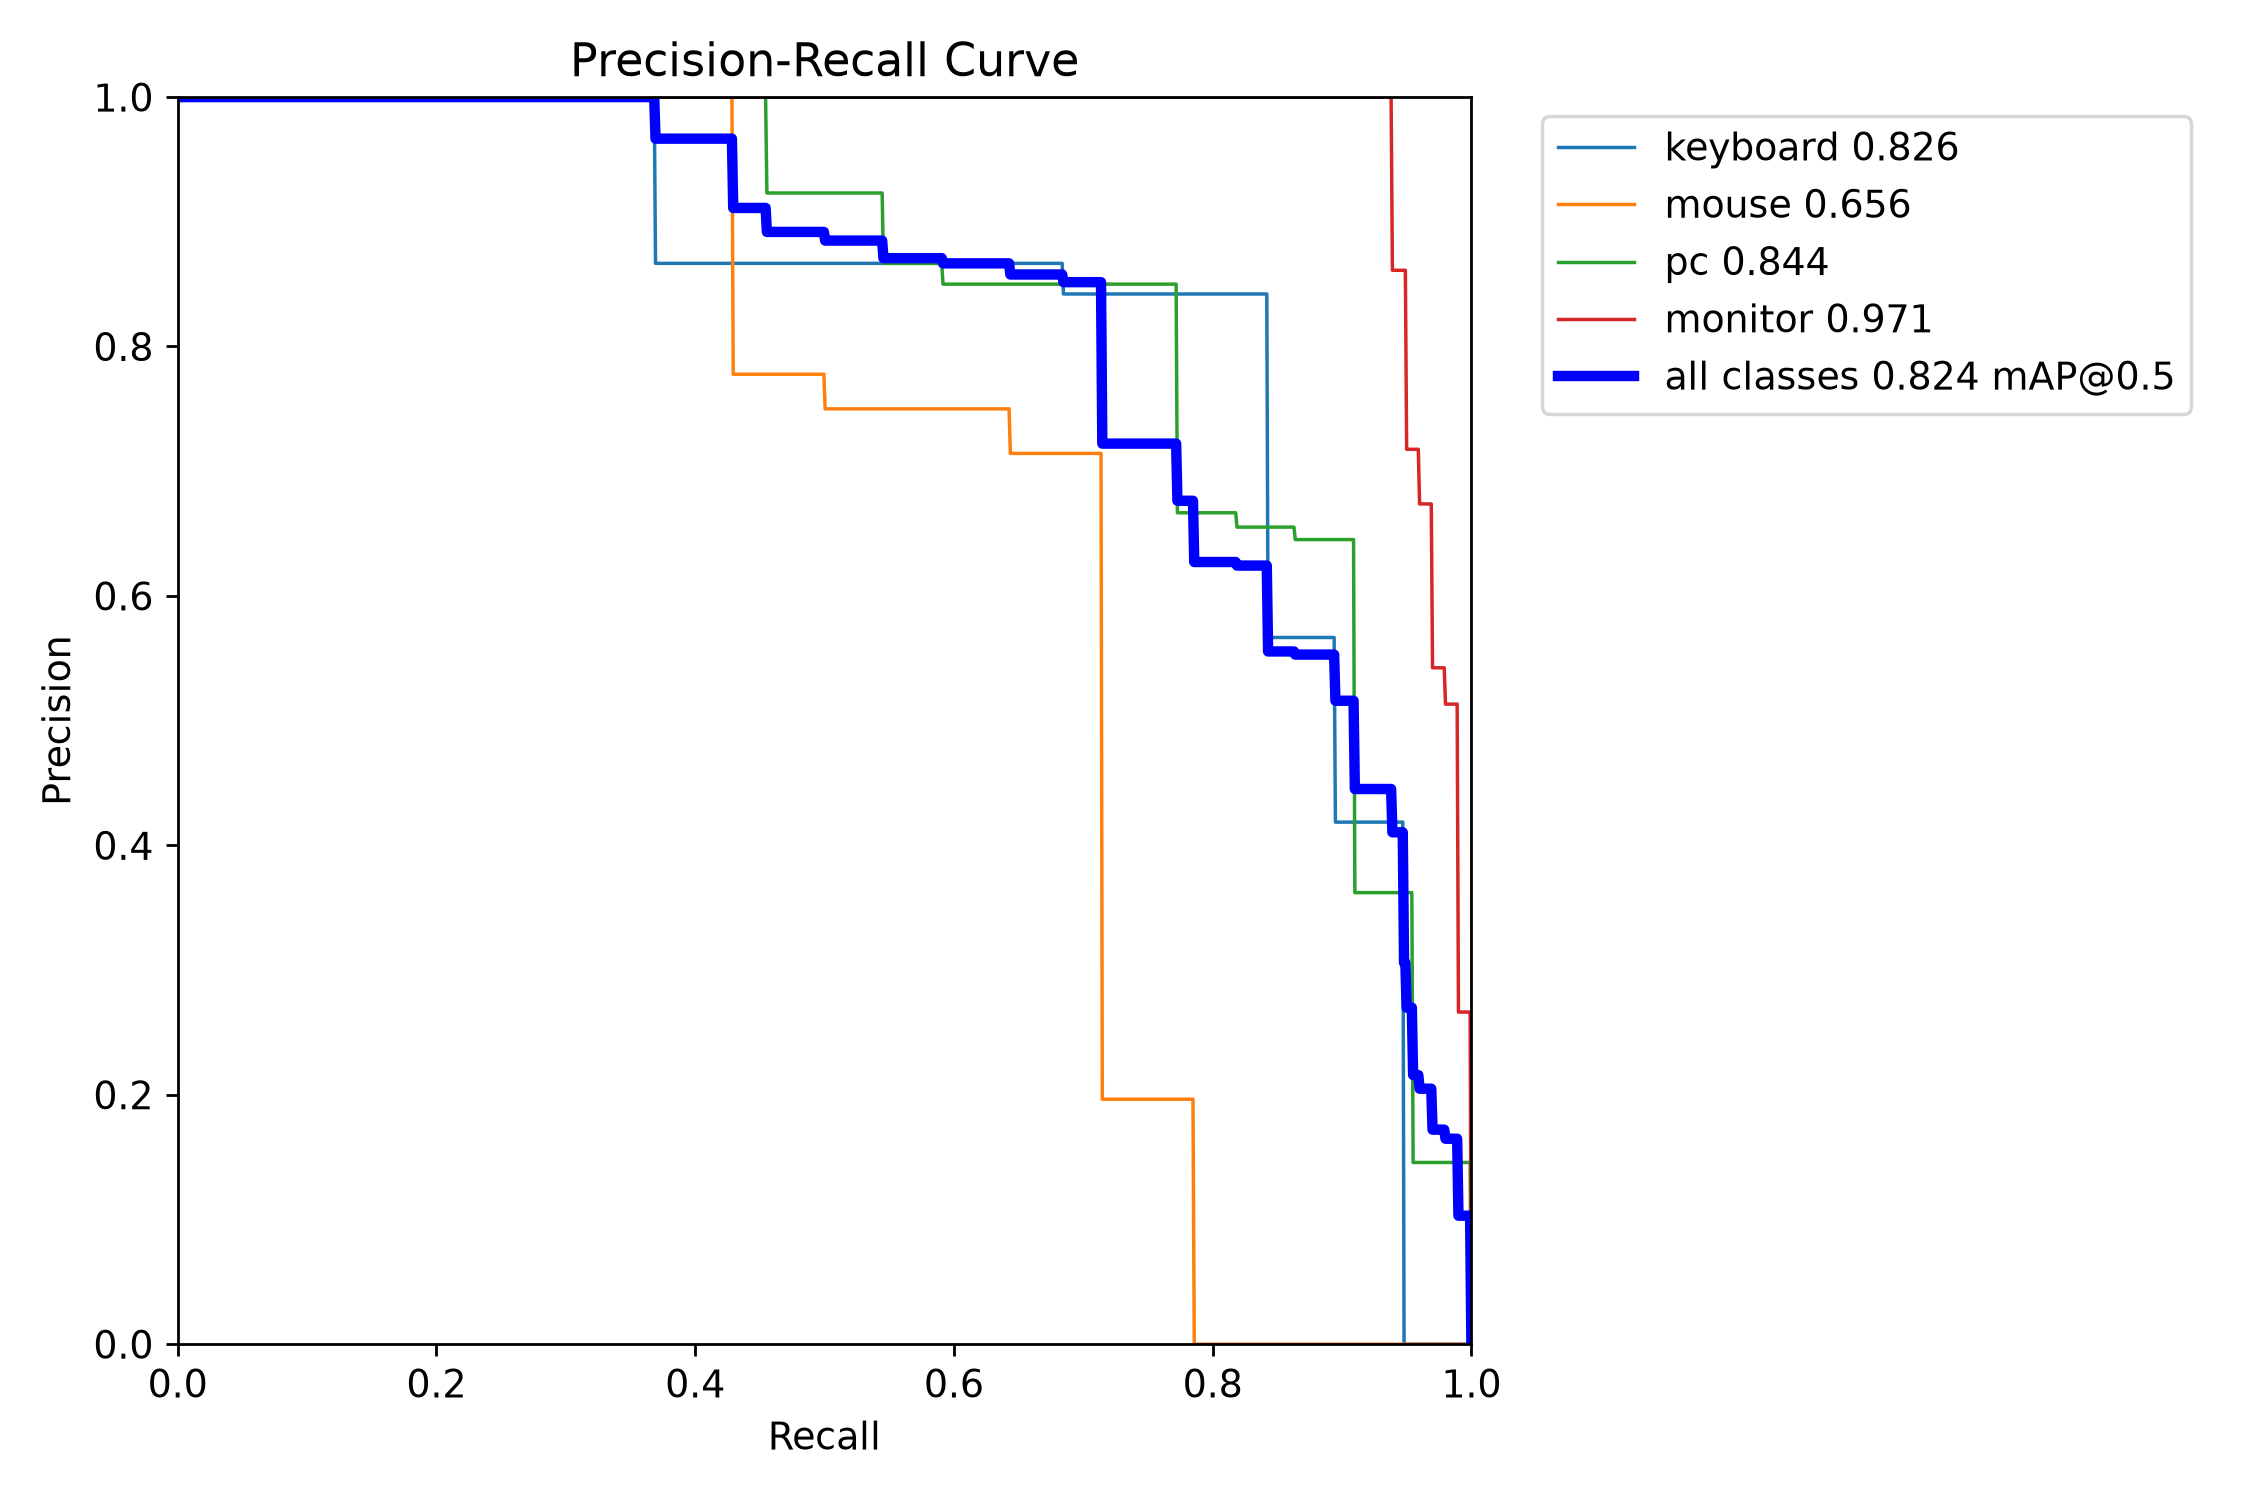

In [7]:
rows = []
def evaluasi(weights, split, label):
    with log_ringkas():
        detector = YOLO(str(weights))
        metrics = detector.val(
            data=str(DATA_YAML), split=split, imgsz=640, batch=8,
            device=DEVICE, workers=0, plots=True, verbose=False,
            project=str(work/'evaluasi'), name=label
        )
    rows.append({'Data':label, 'Precision':metrics.box.mp, 'Recall':metrics.box.mr,
                 'mAP50':metrics.box.map50, 'mAP50-95':metrics.box.map})
    return metrics

TERPILIH = BOBOT_BARU if LATIH_MODEL else BEST
model = YOLO(str(TERPILIH))
assert list(model.names.values()) == names, 'Model harus memiliki empat kelas target.'
CLASS_IDS = list(model.names)
validasi = evaluasi(TERPILIH, 'val', 'Validation')
metrik = evaluasi(TERPILIH, 'test', 'Testing')
kolom_metrik = ['Precision','Recall','mAP50','mAP50-95']
tabel('Evaluasi model akhir', rows, persen=kolom_metrik)
per_kelas = []
for i,cid in enumerate(metrik.box.ap_class_index):
    p,r,ap50,ap = metrik.box.class_result(i)
    per_kelas.append({'Kelas':names[int(cid)], 'Precision':p, 'Recall':r,
                      'mAP50':ap50, 'mAP50-95':ap})
tabel('Metrik per kelas - Testing', per_kelas, persen=kolom_metrik)
image = Path(metrik.save_dir)/'BoxPR_curve.png'
if image.exists():
    display(Image.open(image))


conf,TP,FP,FN,Precision,Recall,F1
0.4000,162,32,66,83.51%,71.05%,76.78%
0.5000,158,26,70,85.87%,69.30%,76.70%
0.6000,154,21,74,88.00%,67.54%,76.43%
0.7000,147,12,81,92.45%,64.47%,75.97%
0.8000,143,9,85,94.08%,62.72%,75.26%


Confidence,Aturan
0.4000,F1 terbaik; target precision 98% belum tercapai


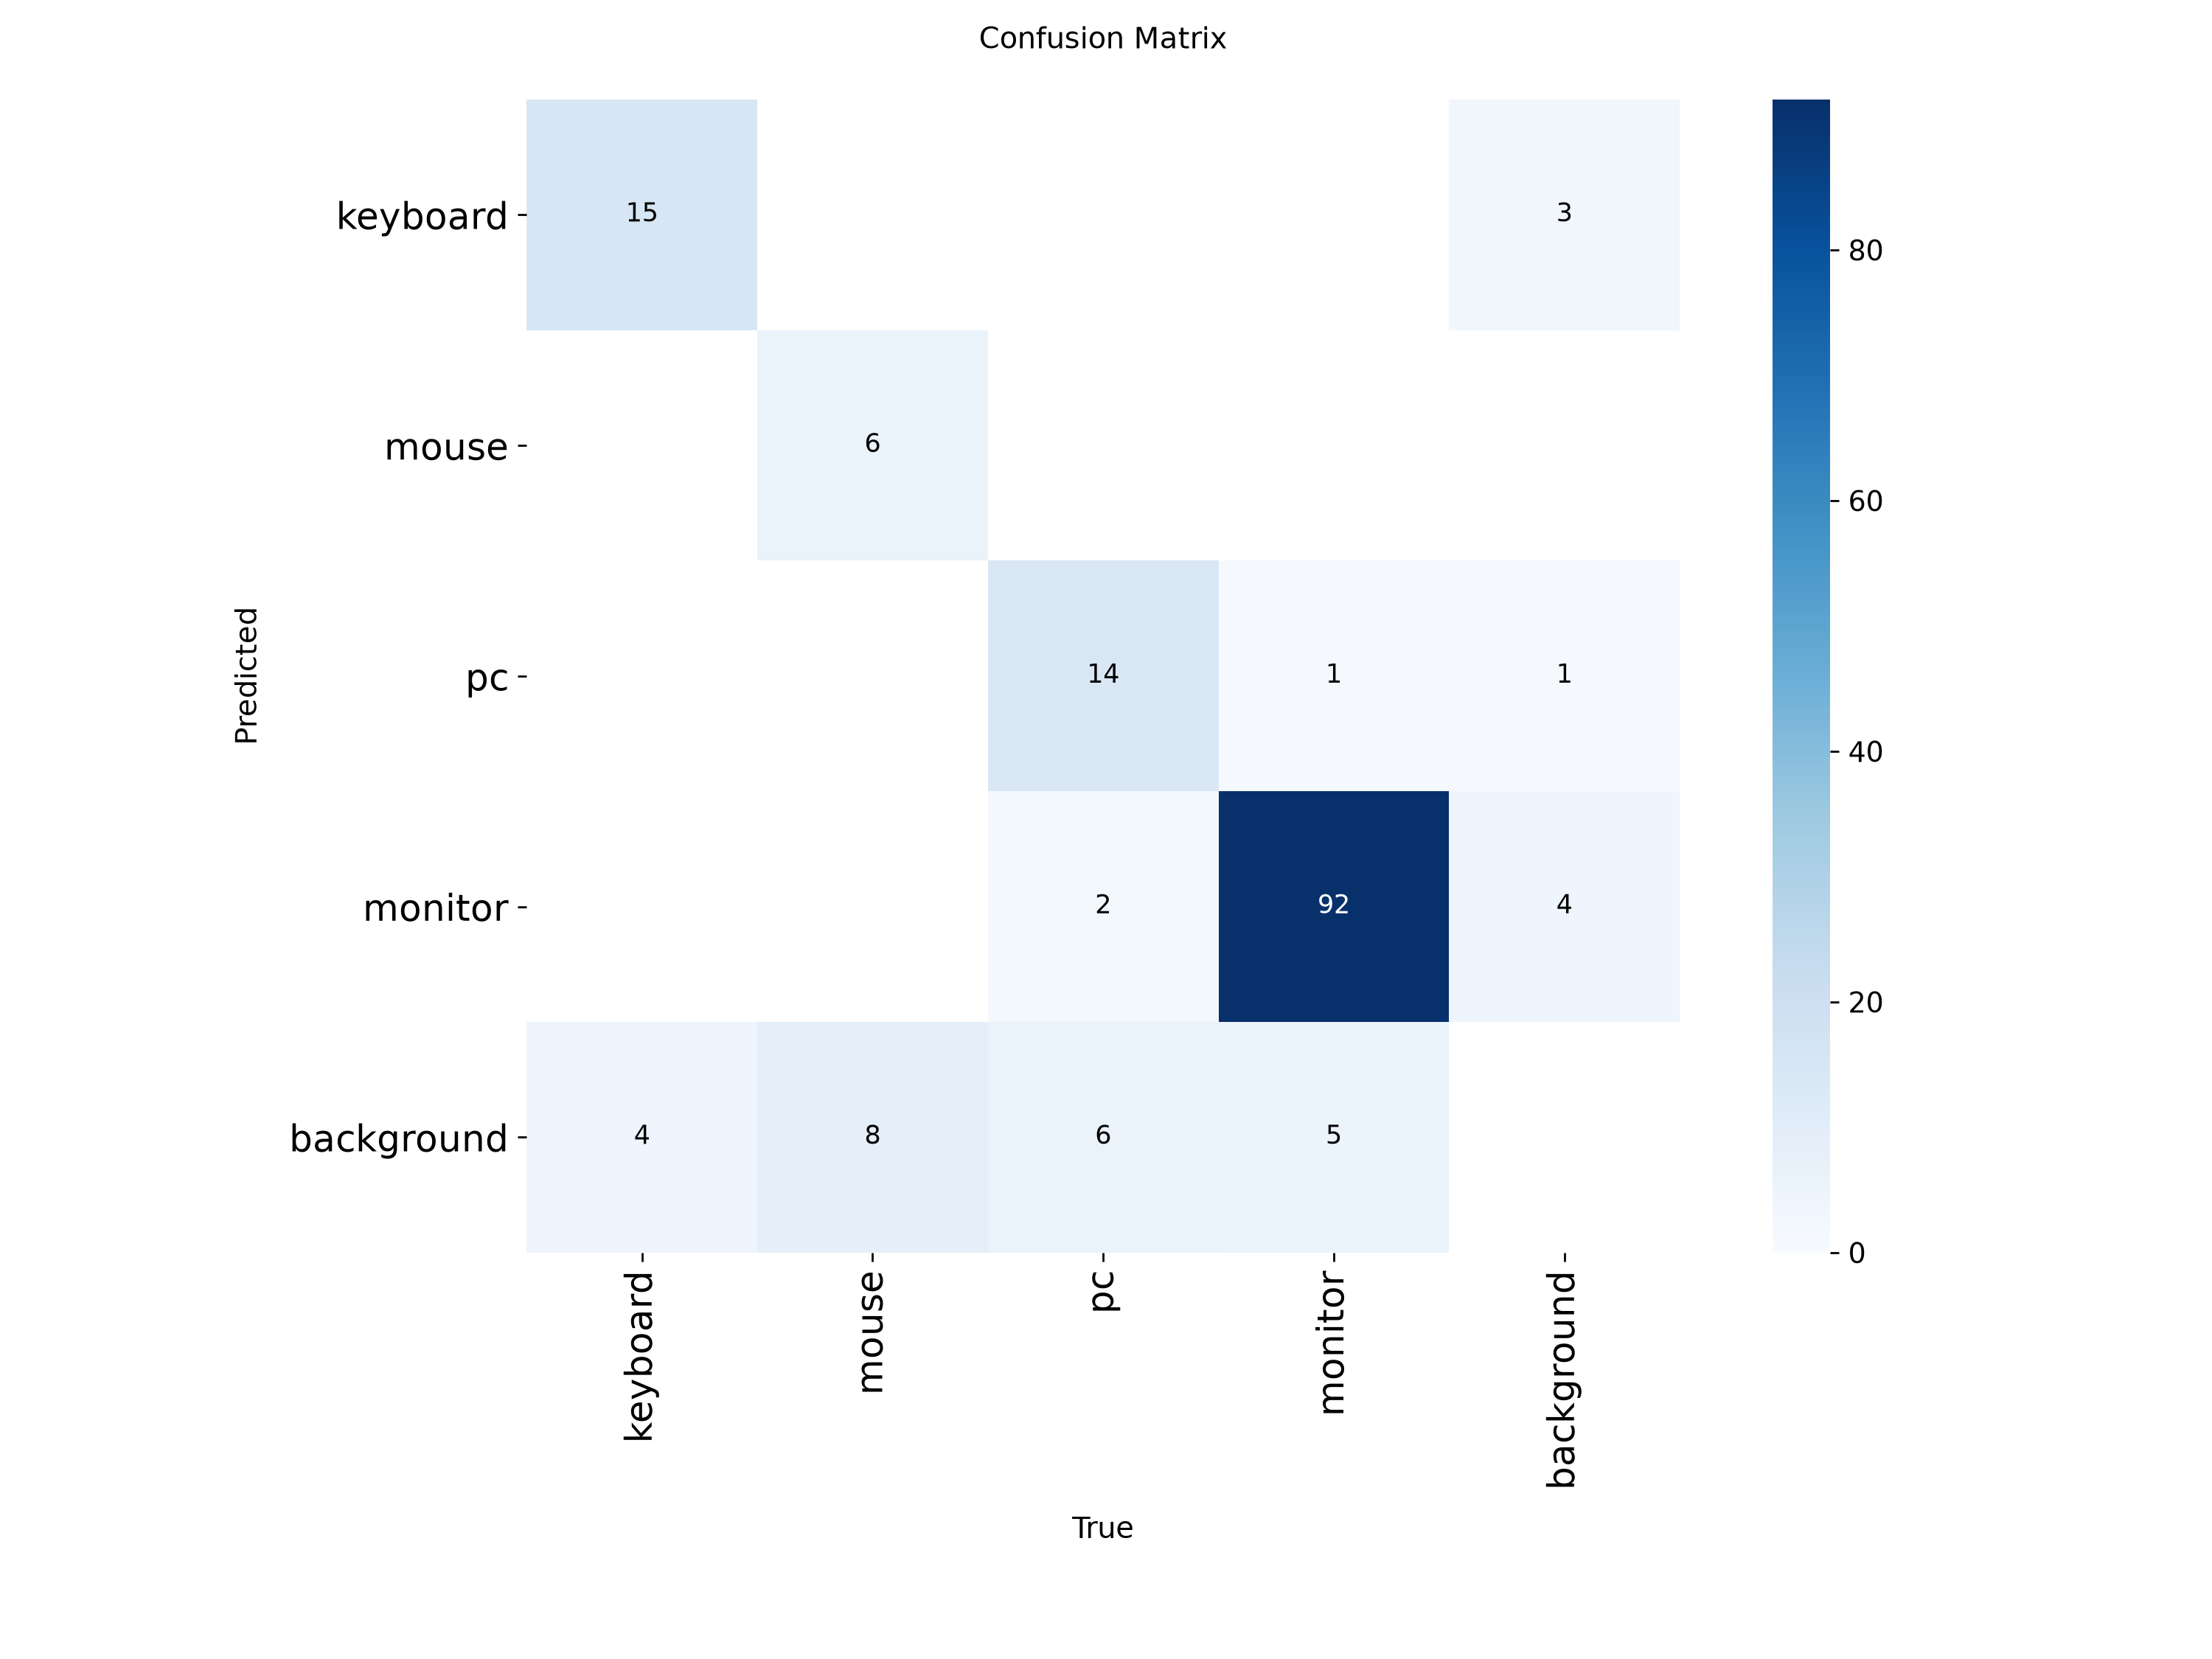

Data,Confidence,Matching IoU
Testing,0.4000,0.4500


In [8]:
valid_images = sorted((work / 'valid/images').glob('*.jpg'))
records = []
for r in model.predict([str(p) for p in valid_images], conf=0.1, classes=CLASS_IDS, iou=0.4, device=DEVICE, stream=True, batch=8, verbose=False):
    path = Path(r.path)
    w, h = Image.open(path).size
    truth = []
    for line in (path.parent.parent / 'labels' / (path.stem + '.txt')).read_text().splitlines():
        if not line.strip():
            continue
        cid, x, y, bw, bh = baca_box(line)
        if cid in CLASS_IDS:
            truth.append((cid, [(x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h]))
    records.append((r.boxes.data.cpu().numpy(), truth))

def overlap(a, b):
    inter = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return inter / max((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter, 1e-09)
calibration = []
for threshold in [0.4, 0.5, 0.6, 0.7, 0.8]:
    tp = fp = fn = 0
    for predictions, truth in records:
        used = set()
        for box in sorted(predictions[predictions[:, 4] >= threshold], key=lambda b: -b[4]):
            matches = [(overlap(box[:4], gt), i) for i, (cid, gt) in enumerate(truth) if cid == int(box[5]) and i not in used]
            score, i = max(matches, default=(0, -1))
            if score >= 0.5:
                tp += 1
                used.add(i)
            else:
                fp += 1
        fn += len(truth) - len(used)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    calibration.append({'conf': threshold, 'TP': tp, 'FP': fp, 'FN': fn, 'Precision': precision, 'Recall': recall, 'F1': 2 * precision * recall / max(precision + recall, 1e-09)})
calibration = pd.DataFrame(calibration)
eligible = calibration[calibration.Precision >= 0.98]
chosen = (eligible.sort_values(['Recall', 'Precision'], ascending=False) if len(eligible) else calibration.sort_values('F1', ascending=False)).iloc[0]
CONF = float(chosen['conf'])
tabel('Kalibrasi confidence pada validation', calibration, persen=['Precision', 'Recall', 'F1'])
tabel(
    'Confidence terpilih',
    [
        {
            'Confidence': CONF,
            'Aturan': 'Precision >= 98%, kemudian recall' if len(eligible) else 'F1 terbaik; target precision 98% belum tercapai',
        },
    ],
)
with log_ringkas():
    operasional = model.val(data=str(DATA_YAML), split='test', classes=CLASS_IDS, conf=CONF, iou=0.4, device=DEVICE, workers=0, batch=8, plots=True, project=str(work / 'evaluasi'), name='operasional')
display(Image.open(Path(operasional.save_dir) / 'confusion_matrix.png'))
tabel(
    'Pengaturan confusion matrix',
    [{'Data': 'Testing', 'Confidence': CONF, 'Matching IoU': 0.45}],
)


## 8. Simpan model

**Tujuan:** Menyimpan bobot terpilih sebagai best.pt dan menyamakan default confidence kamera dengan hasil kalibrasi validation.

In [9]:
if Path(TERPILIH).resolve() != BEST.resolve():
    shutil.copy2(TERPILIH, BEST)
assert BEST.is_file()
model = YOLO(str(BEST))
script = BASE / 'realtime_meja.py'
text = script.read_text(encoding='utf-8')
import re
text = re.sub("(parser.add_argument\\('--conf',type=float,default=)[0-9.]+", lambda m: m.group(1) + f'{CONF:.2f}', text)
text = re.sub('(def kamera_iriun\\(model, CLASS_IDS, DEVICE, conf=)[0-9.]+', lambda m: m.group(1) + f'{CONF:.2f}', text)
script.write_text(text, encoding='utf-8')
tabel(
    'Model tersimpan',
    [
        {
            'File': 'best.pt',
            'Ukuran (MB)': round(BEST.stat().st_size / 1024 ** 2, 2),
            'Jumlah kelas': len(model.names),
            'Confidence kamera': CONF,
            'Status': 'Siap inference',
        },
    ],
)


File,Ukuran (MB),Jumlah kelas,Confidence kamera,Status
best.pt,5.2500,4,0.4000,Siap inference


## 9. Inference

**Tujuan:** Menampilkan bounding box, nama kelas, dan confidence pada gambar test, serta menjalankan kamera Iriun.

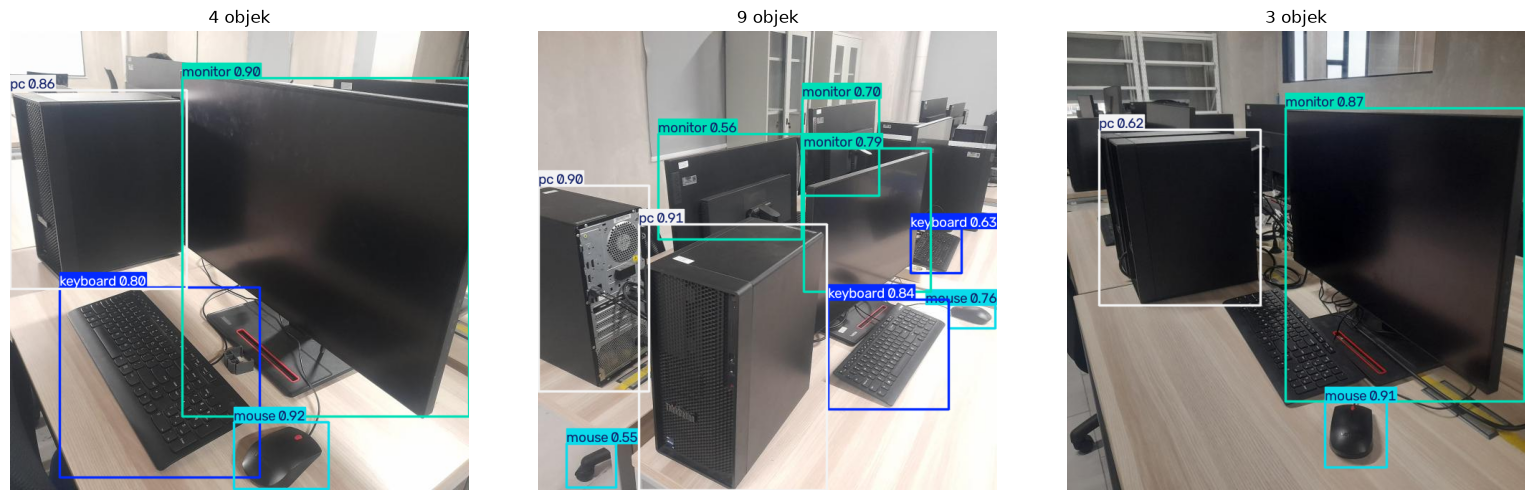

Gambar,Kelas,Confidence
lab_v2_10b3b914-bcb9-4b8f-85ce-cedf8452a774_jpg.rf.8d05c4b662de95c171c60ada4089fd40.jpg,mouse,92.50%
lab_v2_10b3b914-bcb9-4b8f-85ce-cedf8452a774_jpg.rf.8d05c4b662de95c171c60ada4089fd40.jpg,monitor,90.37%
lab_v2_10b3b914-bcb9-4b8f-85ce-cedf8452a774_jpg.rf.8d05c4b662de95c171c60ada4089fd40.jpg,pc,86.20%
lab_v2_10b3b914-bcb9-4b8f-85ce-cedf8452a774_jpg.rf.8d05c4b662de95c171c60ada4089fd40.jpg,keyboard,79.96%
lab_v2_123608e1-d52a-4579-b27c-167cd79c3496_jpg.rf.3387ec9e05bcad5580155a899cb46510.jpg,pc,90.63%
lab_v2_123608e1-d52a-4579-b27c-167cd79c3496_jpg.rf.3387ec9e05bcad5580155a899cb46510.jpg,pc,89.91%
lab_v2_123608e1-d52a-4579-b27c-167cd79c3496_jpg.rf.3387ec9e05bcad5580155a899cb46510.jpg,keyboard,83.76%
lab_v2_123608e1-d52a-4579-b27c-167cd79c3496_jpg.rf.3387ec9e05bcad5580155a899cb46510.jpg,monitor,79.31%
lab_v2_123608e1-d52a-4579-b27c-167cd79c3496_jpg.rf.3387ec9e05bcad5580155a899cb46510.jpg,mouse,75.52%
lab_v2_123608e1-d52a-4579-b27c-167cd79c3496_jpg.rf.3387ec9e05bcad5580155a899cb46510.jpg,monitor,69.69%


In [10]:
samples = sorted((DATASET / 'test/images').glob('*.jpg'))[:3]
ringkasan_inference = []
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, path in zip(axes, samples):
    result = model.predict(str(path), conf=CONF, classes=CLASS_IDS, device=DEVICE, verbose=False)[0]
    for cid, c in zip(result.boxes.cls.tolist(), result.boxes.conf.tolist()):
        ringkasan_inference.append({'Gambar': path.name, 'Kelas': result.names[int(cid)], 'Confidence': c})
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f'{len(result.boxes)} objek')
    ax.axis('off')
plt.tight_layout()
plt.show()
if ringkasan_inference:
    tabel('Rincian hasil inference', ringkasan_inference, persen=['Confidence'])


Jalankan kamera melalui terminal:

```powershell
python realtime_meja.py --kamera iriun
```

Tekan **Q/Esc** untuk keluar. Tombol **+** menaikkan batas confidence dan **-** menurunkannya. Nilai lebih tinggi biasanya mengurangi deteksi salah tetapi dapat melewatkan objek; nilai lebih rendah menampilkan lebih banyak deteksi dengan risiko kesalahan lebih besar. Jika tidak diubah, kamera memakai default hasil kalibrasi validation. Pengaturan ini hanya menyaring prediksi, tidak melatih atau mengubah bobot model.